In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load IPL 2026 batting data (top 100 by runs)
df = pd.read_csv("ipl_2026_batting_top_100.csv")

In [3]:
print("\nFIRST FIVE ROWS")
print(df.head())
print("\nDATASET INFO")
df.info()
print("\nSUMMARY")
print(df[["Matches", "Runs", "Highest_Score", "Strike_Rate", "Fours", "Sixes"]].describe())

print("\nTOP 10 RUN SCORERS")
print(df.nlargest(10, "Runs")[["Player", "Team", "Runs", "Strike_Rate"]])


FIRST FIVE ROWS
   Rank                Player                         Team  Matches  Runs  \
0     1  Vaibhav Sooryavanshi             Rajasthan Royals       16   776   
1     2          Shubman Gill               Gujarat Titans       16   732   
2     3       B Sai Sudharsan               Gujarat Titans       17   722   
3     4           Virat Kohli  Royal Challengers Bengaluru       16   675   
4     5      Heinrich Klaasen          Sunrisers Hyderabad       15   624   

   Highest_Score  Strike_Rate  Fours  Sixes  
0            103        237.3     63     72  
1            104        163.0     74     33  
2            100        158.0     75     30  
3            105        165.8     73     25  
4             69        160.0     48     31  

DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Rank           100 non-null    int64  
 1   P

<ipython-input-4-9a4a49a51800>:8: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("top_10_run_scorers.png", dpi=300)
<ipython-input-4-9a4a49a51800>:8: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("top_10_run_scorers.png", dpi=300)


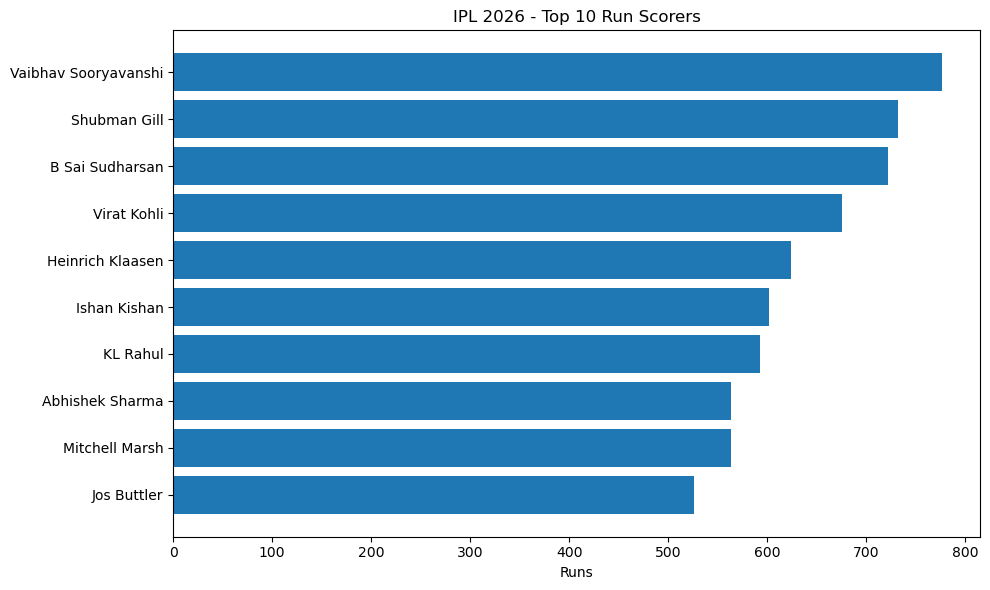

In [4]:
# Plot 1: Top 10 run scorers
top = df.nlargest(10, "Runs").sort_values("Runs")
plt.figure(figsize=(10, 6))
plt.barh(top["Player"], top["Runs"])
plt.title("IPL 2026 - Top 10 Run Scorers")
plt.xlabel("Runs")
plt.tight_layout()
plt.savefig("top_10_run_scorers.png", dpi=300)
plt.show()

<ipython-input-5-dc77570b9bc7>:8: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("runs_vs_strike_rate.png", dpi=300)
<ipython-input-5-dc77570b9bc7>:8: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("runs_vs_strike_rate.png", dpi=300)


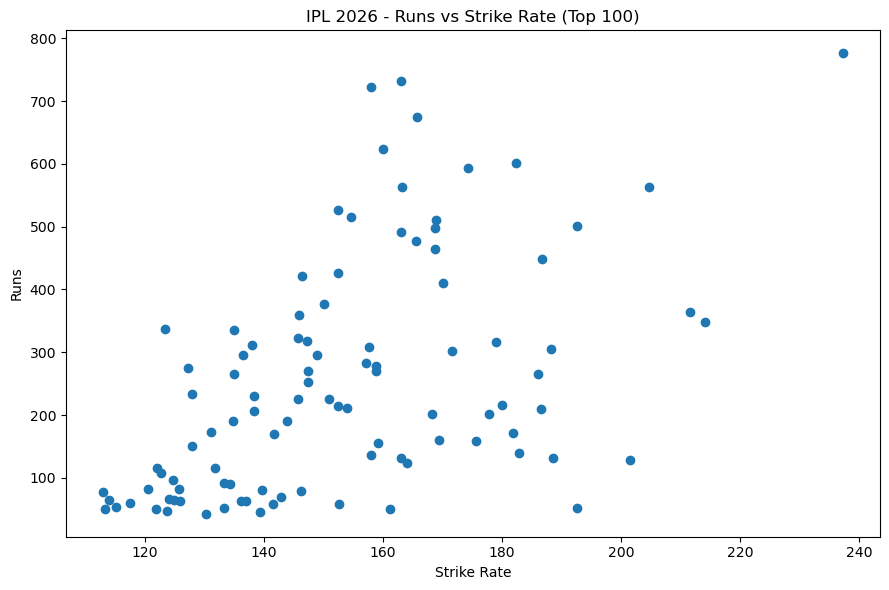

In [5]:
# Plot 2: Runs vs strike rate
plt.figure(figsize=(9, 6))
plt.scatter(df["Strike_Rate"], df["Runs"])
plt.title("IPL 2026 - Runs vs Strike Rate (Top 100)")
plt.xlabel("Strike Rate")
plt.ylabel("Runs")
plt.tight_layout()
plt.savefig("runs_vs_strike_rate.png", dpi=300)
plt.show()


<ipython-input-6-fef1cfcde677>:8: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("boundary_runs_top10.png", dpi=300)
<ipython-input-6-fef1cfcde677>:8: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("boundary_runs_top10.png", dpi=300)


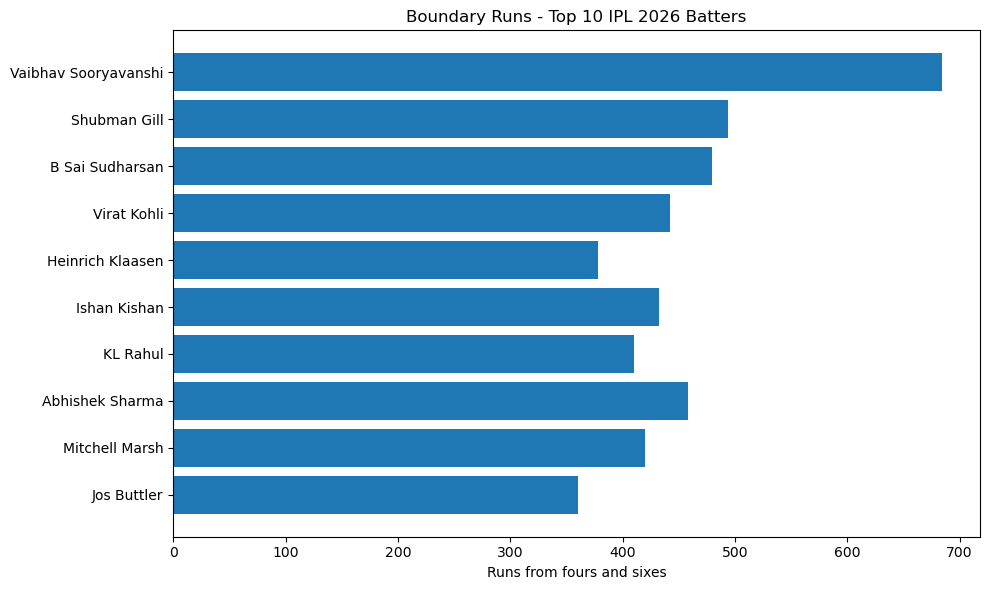

In [6]:
# Plot 3: Boundary runs among top 10 run scorers
top["Boundary_Runs"] = top["Fours"] * 4 + top["Sixes"] * 6
plt.figure(figsize=(10, 6))
plt.barh(top["Player"], top["Boundary_Runs"])
plt.title("Boundary Runs - Top 10 IPL 2026 Batters")
plt.xlabel("Runs from fours and sixes")
plt.tight_layout()
plt.savefig("boundary_runs_top10.png", dpi=300)
plt.show()

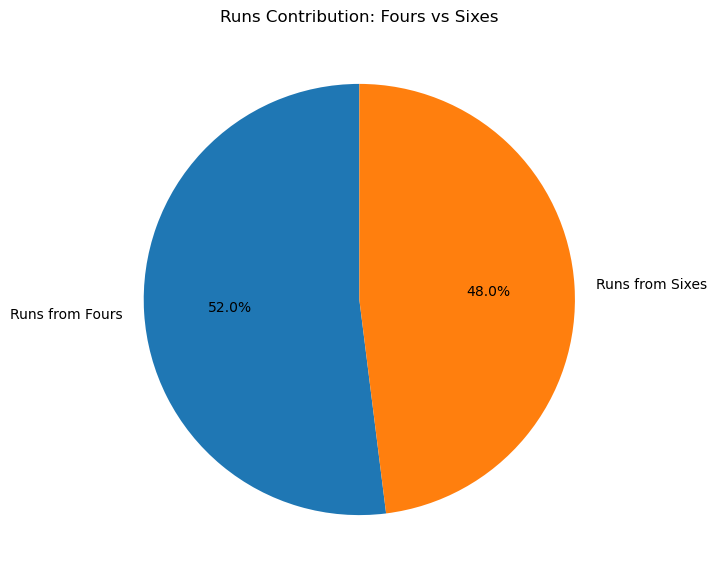

In [7]:
# 1. Fours vs Sixes
four_runs = (df["Fours"] * 4).sum()
six_runs = (df["Sixes"] * 6).sum()

plt.figure(figsize=(7, 7))
plt.pie(
    [four_runs, six_runs],
    labels=["Runs from Fours", "Runs from Sixes"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Runs Contribution: Fours vs Sixes")
plt.show()




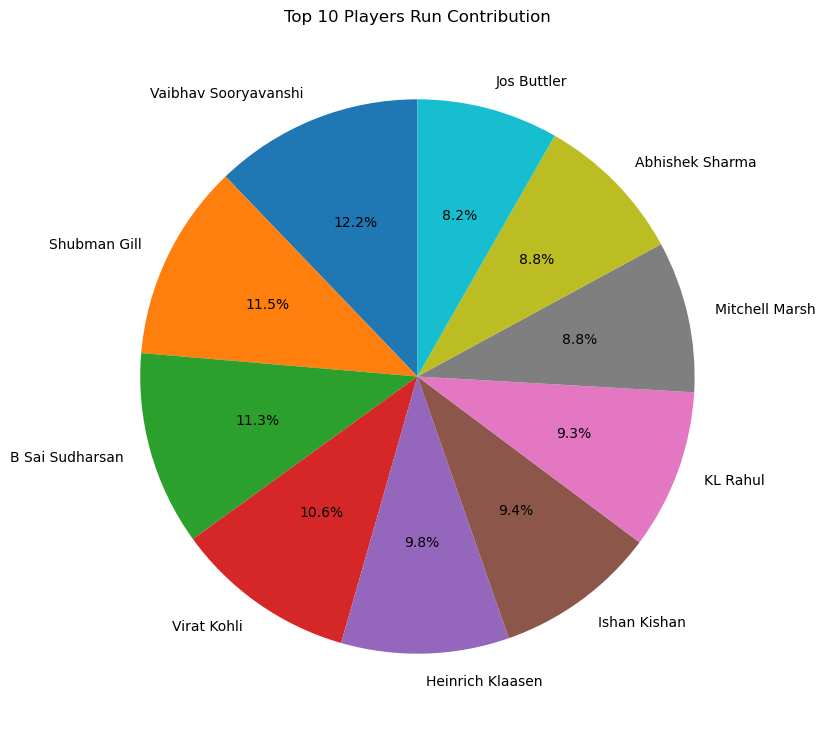

In [8]:

# 2. Top 10 Players Run Contribution
top10 = df.nlargest(10, "Runs")

plt.figure(figsize=(9, 9))
plt.pie(
    top10["Runs"],
    labels=top10["Player"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Top 10 Players Run Contribution")
plt.show()


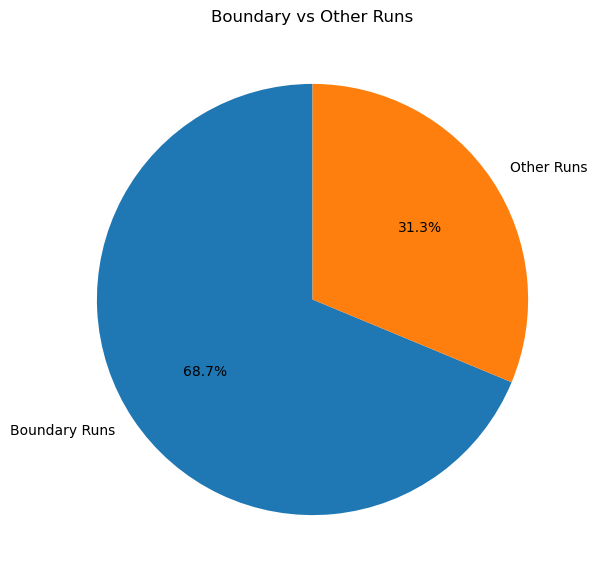

In [9]:

# 3. Boundary vs Other Runs
total_runs = df["Runs"].sum()
boundary_runs = four_runs + six_runs
other_runs = total_runs - boundary_runs

plt.figure(figsize=(7, 7))
plt.pie(
    [boundary_runs, other_runs],
    labels=["Boundary Runs", "Other Runs"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Boundary vs Other Runs")
plt.show()

In [10]:
df.to_csv("ipl_2026_top100_cleaned.csv", index=False)
print("\nAnalysis complete.")


Analysis complete.
